# 01 · Datos y bases (semilla 42)

Parte 1 de 3 del `02_DS02_ensemble_RUL.ipynb` original. Mismo código, mismo orden.

**Corre de arriba abajo.** Tarda la primera parte lenta (`run_seed` semilla 42). Al final guarda en `artifacts/` lo que necesitan los cuadernos 02 y 03.

Orden: `01` → `02` → `03`.

# 02. N-CMAPSS DS02 — Ensamble de stacking híbrido (protocolo honesto)

**Qué predecimos.** La vida útil restante (RUL) de un motor turbofán, en ciclos
de vuelo, a partir de una ventana de 50 lecturas de sensores.

- **Tipo de problema:** regresión sobre series temporales, con los motores
  agrupados: ninguna ventana de un motor aparece a la vez en ajuste y en test.
- **Métrica principal:** RMSE, en ciclos. Se informan también MAE, R² y la
  puntuación asimétrica de la NASA, que castiga más pasarse de RUL que quedarse
  corto.
- **Qué vas a hacer:** ejecutar las celdas en orden y leer lo que imprimen. El
  código ya está escrito; el trabajo es interpretar tablas y gráficos.
- **Lo que cambia en esta revisión:** el protocolo, no el modelo. Los números de
  la versión anterior no eran comparables porque había fuga de información.

**Qué es.** Un predictor de RUL para N-CMAPSS DS02 construido como ensamble de
stacking: un BiLSTM sobre ventanas ordenadas, un LightGBM cuantílico sobre un
resumen tabular residualizado, un meta-aprendiz, un factor de contracción
`beta` y una EMA causal por motor.

**Qué cambió en esta revisión** (la versión anterior conservaba los números pero
no el protocolo):

| Defecto | Corrección |
| --- | --- |
| `scaler`, `scaler_w`, `poly_w` y los 14 `Ridge` de residuos se ajustaban sobre los seis motores dev, holdout incluido | El reparto por motor ocurre ahora **primero**; toda transformación se ajusta solo con los cinco motores de ajuste |
| `beta` se elegía sobre las mismas filas del motor 16 que ajustaron los meta-aprendices (RMSE de validación 0,308 frente a 4,221 del BiLSTM) | `beta` se elige por validación cruzada agrupada **fuera de fold**; el protocolo dentro de muestra se conserva solo como diagnóstico etiquetado |
| `ensemble.joblib` no se podía cargar fuera del notebook (`__main__`) y su `Lambda` lo ataba a una versión menor de Python | Las clases viven en `src/ds02_rul`; el grafo se persiste de forma nativa como `.keras` con una capa de pooling registrada |
| El fallback de FD001 podía sobrescribir en silencio el artefacto de DS02 | El cargador lanza un error en vez de hacer fallback |
| Las afirmaciones sobre el costo de `cyc_norm` se citaban de una iteración no relacionada | La ablación de abajo lo **mide** |

Todo lo de acá es un único diseño medido con tres semillas: la dispersión entre
semillas se informa al lado de la media para que no se confunda con precisión.


## 0 · Entorno y semillas

Dos avisos antes de empezar:

- **Duración.** El notebook completo tarda unos 30 minutos. Cuatro celdas se
  llevan casi todo el tiempo: `run_seed` (sección 5), la ablación (sección 6),
  las predicciones fuera de fold (sección 7) y las dos semillas extra
  (sección 9). Cada una imprime lo que tardó.
- **Orden.** Las secciones se ejecutan de arriba abajo. Ninguna celda funciona
  suelta: todas leen variables que dejó la anterior.


In [1]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


### Utilidades de presentación

Las funciones de abajo no entrenan nada: reciben tablas y predicciones ya
calculadas y solo las formatean o las dibujan. Están acá arriba para que el
resto del notebook se lea como una narración y no como veinte celdas sueltas:
cambiar un color o un decimal se hace en un solo sitio.


In [2]:
# --- utilidades de presentación: importaciones ---
# `plt` se importa aquí, no en la celda de persistencia: las funciones
# de abajo lo usan y esa celda se ejecuta después de todos los gráficos.
import matplotlib.pyplot as plt

# --- paleta y etiquetas -----------------------------------------------------
# Un color por modelo, el mismo en todos los gráficos. Así el lector reconoce
# la serie sin volver a leer la leyenda.
PALETA = {
    'LightGBM solo': '#8C8C8C',
    'BiLSTM solo': '#4C72B0',
    'Híbrido + EMA5': '#1FA098',
}
COLORES_ABLACION = {'LGBM': '#8C8C8C', 'BiLSTM': '#4C72B0', 'BiLSTM+EMA': '#1FA098'}
NOMBRE_CORTO = {'LightGBM solo': 'LightGBM', 'BiLSTM solo': 'BiLSTM'}


def nombre_corto(modelo):
    """Etiqueta corta para los ejes; no toca el nombre que usan las tablas."""
    return NOMBRE_CORTO.get(modelo, modelo)


# --- tablas -----------------------------------------------------------------
def tabla_modelos(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score')):
    """Una fila por modelo con 'media ± desviación' en cada métrica.

    Ordena por RMSE medio y devuelve strings: es una tabla para leer, no para
    volver a calcular. Los decimales se eligen por métrica para que el ruido de
    las últimas cifras no se confunda con una diferencia.
    """
    orden = summary.sort_values('RMSE_mean')
    filas = []
    for _, fila in orden.iterrows():
        registro = {'Modelo': fila['Modelo']}
        for metrica in metricas:
            decimales = {'R2': 4, 'NASA_Score': 1}.get(metrica, 3)
            registro[metrica] = (f"{fila[f'{metrica}_mean']:.{decimales}f}"
                                 f" ± {fila[f'{metrica}_std']:.{decimales}f}")
        filas.append(registro)
    return pd.DataFrame(filas)


def comparar_con_base(summary, base, metricas=('RMSE', 'MAE')):
    """Cuánto mejora (o empeora) cada modelo frente a la base indicada.

    El delta es la diferencia directa de medias: negativo en RMSE/MAE significa
    que se equivoca menos. La columna 'mejora %' ya viene en positivo cuando
    mejora, para poder decirla en voz alta sin cambiar de signo.
    """
    fila_base = summary.loc[summary['Modelo'] == base].iloc[0]
    filas = []
    for _, fila in summary.sort_values('RMSE_mean').iterrows():
        registro = {'Modelo': fila['Modelo'], 'frente a': base}
        for metrica in metricas:
            delta = fila[f'{metrica}_mean'] - fila_base[f'{metrica}_mean']
            registro[f'delta {metrica}'] = round(float(delta), 3)
            registro[f'mejora {metrica} %'] = round(-100 * float(delta) / float(fila_base[f'{metrica}_mean']), 1)
        filas.append(registro)
    return pd.DataFrame(filas)


def tabla_por_motor(y_real, y_pred, unidades):
    """RMSE, MAE y sesgo de cada motor de test, por separado.

    Un promedio bueno puede esconder un motor malo: si un motor concentra el
    error, el número global no describe al modelo.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    unidades = np.asarray(unidades)
    filas = []
    for unidad in sorted(np.unique(unidades).tolist()):
        mask = unidades == unidad
        error = y_pred[mask] - y_real[mask]
        filas.append({
            'Motor': int(unidad),
            'Ventanas': int(mask.sum()),
            'RMSE': round(float(np.sqrt(np.mean(error ** 2))), 3),
            'MAE': round(float(np.mean(np.abs(error))), 3),
            'Sesgo': round(float(error.mean()), 3),
        })
    return pd.DataFrame(filas)


# --- gráficos ---------------------------------------------------------------
def barras_metricas(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score'), figsize=(11, 7)):
    """Barras horizontales de la media, con la desviación entre semillas como error.

    La rayita es la desviación: si dos barras se diferencian menos que eso, es
    un empate y no hay que elegir por el tercer decimal.
    """
    orden = summary.sort_values('RMSE_mean')
    etiquetas = [nombre_corto(m) for m in orden['Modelo']]
    colores = [PALETA.get(m, '#999999') for m in orden['Modelo']]

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for ax, metrica in zip(axes.ravel(), metricas):
        ax.barh(etiquetas, orden[f'{metrica}_mean'].values,
                xerr=orden[f'{metrica}_std'].values, color=colores, capsize=5)
        ax.set_title(metrica)
        ax.set_xlabel('media ± desviación entre semillas')
        ax.grid(True, axis='x', ls='--', alpha=0.5)
        ax.invert_yaxis()
    fig.suptitle('Comparación de modelos sobre los motores 11/14/15', y=1.01)
    plt.tight_layout()
    plt.show()


def dispersion_por_semilla(seed_rows, metrica='RMSE', figsize=(9, 4)):
    """Un punto por semilla y una línea con la media.

    Si los puntos se abren mucho, el promedio no alcanza: hay que decir cuánto
    varía el modelo antes de declararlo ganador.
    """
    df = pd.DataFrame(seed_rows)
    modelos = [m for m in PALETA if m in set(df['Modelo'])]
    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        valores = df.loc[df['Modelo'] == modelo, metrica].values
        if len(valores) == 0:
            continue
        x = np.full(len(valores), i) + np.linspace(-0.06, 0.06, len(valores))
        ax.scatter(x, valores, s=80, color=PALETA[modelo], zorder=3)
        ax.hlines(valores.mean(), i - 0.22, i + 0.22, color='black', lw=1.8)
        ax.annotate(f'{valores.mean():.3f}', (i, valores.mean()),
                    textcoords='offset points', xytext=(0, 12), ha='center')
    ax.set_xticks(range(len(modelos)))
    ax.set_xticklabels([nombre_corto(m) for m in modelos])
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por semilla — cada punto es una semilla, la línea es la media')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


def barras_ablacion(abl, metrica='RMSE', figsize=(11, 4.5)):
    """Barras agrupadas: una variante de la ablación por grupo, un modelo por barra.

    Responde una sola pregunta: cuánto cambia la métrica al quitar el contador
    de ciclos o al usar la línea base por motor.
    """
    tabla = abl.pivot(index='variant', columns='model', values=metrica)
    modelos = list(tabla.columns)
    posiciones = np.arange(len(tabla.index))
    ancho = 0.8 / len(modelos)

    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        ax.bar(posiciones + i * ancho - 0.4 + ancho / 2, tabla[modelo].values,
               width=ancho, label=modelo,
               color=COLORES_ABLACION.get(modelo, '#999999'))
    ax.set_xticks(posiciones)
    ax.set_xticklabels([v.replace('  ', ' ') for v in tabla.index], rotation=12, ha='right')
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por variante de la ablación (más corta es mejor)')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend(title='modelo')
    plt.tight_layout()
    plt.show()
    return tabla


def real_vs_predicho(y_real, y_pred, titulo, figsize=(6.5, 6)):
    """Dispersión predicción frente a realidad, con la diagonal identidad.

    Un modelo perfecto pone todos los puntos sobre la diagonal. Lo que importa
    no es el punto individual sino la forma de la nube: si se abre en abanico
    hacia la derecha, el error crece con la RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_real
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    r2 = float(1 - np.sum(error ** 2) / np.sum((y_real - y_real.mean()) ** 2))
    limite = float(max(y_real.max(), y_pred.max()) * 1.05)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_real, y_pred, s=10, alpha=0.35, color='#1FA098', edgecolors='none')
    ax.plot([0, limite], [0, limite], 'k--', lw=1.4, label='predicción perfecta')
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('RUL predicha (ciclos)')
    ax.set_title(titulo)
    ax.text(0.03, 0.97, f'RMSE {rmse:.2f}\nMAE {mae:.2f}\nR² {r2:.3f}',
            transform=ax.transAxes, va='top',
            bbox=dict(boxstyle='round', fc='white', ec='#cccccc'))
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def residuos(y_real, y_pred, titulo='Residuos', figsize=(9, 4)):
    """Error (predicho − real) frente a la predicción, con la banda de ±1 desviación.

    Si la nube está centrada en cero, el modelo no tiene sesgo global. Si se
    abre a un lado, el error depende del nivel de RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuo = y_pred - y_real

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_pred, residuo, s=9, alpha=0.3, color='#4C72B0', edgecolors='none')
    ax.axhline(0, color='black', lw=1.2)
    ax.axhline(residuo.mean(), color='#C44E52', lw=1.3, ls='--',
               label=f'sesgo {residuo.mean():+.2f}')
    ax.fill_between([0, float(y_pred.max())], -residuo.std(), residuo.std(),
                    color='#4C72B0', alpha=0.10, label=f'±1 desv ({residuo.std():.2f})')
    ax.set_xlabel('RUL predicha (ciclos)')
    ax.set_ylabel('predicho − real')
    ax.set_title(titulo)
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def error_por_tramo(y_real, y_pred, tramos=(0, 25, 50, 75, 100, 500), figsize=(9, 4)):
    """MAE en cada tramo de RUL real: dice dónde duele el error.

    Cada barra es un rango de RUL real. Si el MAE crece hacia la derecha, el
    modelo acierta cerca del fallo y se pierde cuando al motor le queda vida.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    filas = []
    for bajo, alto in zip(tramos[:-1], tramos[1:]):
        mask = (y_real >= bajo) & (y_real < alto)
        if mask.sum() == 0:
            continue
        filas.append({
            'tramo de RUL': f'[{bajo}, {alto})',
            'ventanas': int(mask.sum()),
            'MAE': round(float(np.mean(np.abs(y_real[mask] - y_pred[mask]))), 3),
        })
    tabla = pd.DataFrame(filas)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(tabla['tramo de RUL'], tabla['MAE'], color='#1FA098')
    for i, valor in enumerate(tabla['MAE']):
        ax.annotate(f'{valor:.2f}', (i, valor), textcoords='offset points',
                    xytext=(0, 4), ha='center')
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('MAE del tramo')
    ax.set_title('¿Dónde falla el modelo? MAE por tramo de RUL real')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    return tabla


def curva_entrenamiento(historial, figsize=(8, 4)):
    """Pérdida de entrenamiento y de validación por época.

    Si la de validación deja de bajar mientras la de entrenamiento sigue
    cayendo, el modelo empieza a memorizar; el early stopping corta ahí.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(historial['loss'], marker='o', label='entrenamiento', color='#4C72B0')
    ax.plot(historial['val_loss'], marker='s', label='validación (motor 16)', color='#C44E52')
    mejor = int(np.argmin(historial['val_loss']))
    ax.scatter([mejor], [historial['val_loss'][mejor]], s=150, facecolors='none',
               edgecolors='black', zorder=3, label=f'mejor época ({mejor + 1})')
    ax.set_xlabel('época')
    ax.set_ylabel('pérdida (MSE)')
    ax.set_title('Curva de entrenamiento del BiLSTM')
    ax.grid(True, ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


def beta_por_fold(selection, figsize=(7, 4)):
    """El beta elegido en cada fold, con la mediana como línea de referencia.

    Si los folds no coinciden, el beta no está bien determinado: conviene decirlo
    en vez de informar un único número como si fuera estable.
    """
    folds = selection['folds']
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar([f"fold {f['fold']}" for f in folds], [f['beta'] for f in folds], color='#1FA098')
    ax.axhline(selection['beta'], color='black', ls='--', lw=1.4,
               label=f"mediana {selection['beta']:.2f}")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('beta elegido')
    ax.set_title('beta fuera de fold: ¿coinciden los folds?')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


### Compatibilidad estilo clase (solo presentacion)

`evaluar_clase` y `mostrar_clase` son alias de lo que ya usas (`evaluate_predictions`, `tabla_modelos`).
No entrenan nada ni cambian numeros: solo devuelven la misma fila y la pintan redondeada, como el `evaluar()/mostrar()` de RequisitosClase.


In [3]:
# Fase A — envoltorios estilo clase (SOLO presentacion: no re-entrena, no cambia metricas)
def evaluar_clase(nombre, y_true, y_pred):
    """Alias de evaluate_predictions: misma fila, nombre estilo clase."""
    return evaluate_predictions(np.asarray(y_true), np.asarray(y_pred), nombre)

def mostrar_clase(filas, orden_por="RMSE"):
    """Ordena la tabla como en clase (mejor arriba) y la redondea. Solo lectura."""
    t = pd.DataFrame(filas).sort_values(orden_por, ascending=True).reset_index(drop=True)
    display(t.round(3))
    return t
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


## 1 · Los datos y el reparto por motor

El reparto se declara **antes** de calcular cualquier estadístico. Nada aguas
abajo puede mirar motores que no le corresponden:

| Partición | Motores | Rol |
| --- | --- | --- |
| ajuste | 2, 5, 10, 18, 20 | aquí se ajusta todo: escalados, base polinómica, ridges de residuos y los dos modelos base |
| holdout | 16 | early stopping del BiLSTM y ajuste del meta-aprendiz |
| test | 11, 14, 15 | se puntúa una sola vez, no se ajusta nada, ni siquiera un escalador |

`STRIDE = 100`. Con unas 114 filas muestreadas por ciclo de vuelo, una ventana
de 50 filas cubre **0,44 ciclos de vuelo**; es una foto de alta frecuencia de la
degradación, no 50 ciclos de historia. El nombre lo dice.


In [4]:
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]

raw = load_ds02(stride=100)
print('dataset:', raw['path'])
print('canales W  :', raw['op_names'])
print('canales Xs :', raw['sensor_names'])

units_dev = raw['A_train'][:, 0]
units_test = raw['A_test'][:, 0]
print()
print('motores dev :', sorted(np.unique(units_dev).tolist()), '| filas', len(units_dev))
print('motores test:', sorted(np.unique(units_test).tolist()), '| filas', len(units_test))

assert sorted(np.unique(units_dev).tolist()) == sorted(FIT_UNITS + HOLDOUT_UNITS)
assert sorted(np.unique(units_test).tolist()) == TEST_UNITS
assert not set(FIT_UNITS + HOLDOUT_UNITS) & set(TEST_UNITS)

n_dev_rows = int(np.isin(units_dev, FIT_UNITS).sum())
print(f'filas de ajuste: {n_dev_rows} | filas de holdout: {int(np.isin(units_dev, HOLDOUT_UNITS).sum())}')


dataset: archive/CCMaps/N-CMAPSS_DS02-006.h5
canales W  : ['alt', 'Mach', 'TRA', 'T2']
canales Xs : ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']

motores dev : [2.0, 5.0, 10.0, 16.0, 18.0, 20.0] | filas 52635
motores test: [11.0, 14.0, 15.0] | filas 12538
filas de ajuste: 44982 | filas de holdout: 7653


## 2 · Preprocesado sin fuga de información

La residualización plantea una pregunta física —*¿cuánto de esta lectura del
sensor explican la altitud, el Mach, el empuje y la temperatura total?*— y resta
la respuesta. Los `Ridge` que la estiman tienen que ajustarse solo con los
motores de ajuste, y eso es lo que recibe `fit_preprocessing` aquí abajo.

Es la línea más importante del notebook: todo lo demás cuelga de ella.


In [5]:
fit_rows = np.isin(raw['A_train'][:, 0], FIT_UNITS)
hold_rows = np.isin(raw['A_train'][:, 0], HOLDOUT_UNITS)

assert fit_rows.sum() + hold_rows.sum() == len(fit_rows)

prep = fit_preprocessing(raw['W_train'][fit_rows], raw['Xs_train'][fit_rows])

print('escalador ajustado con :', prep['scaler'].n_features_in_, 'canales,',
      int(prep['scaler'].n_samples_seen_), 'filas (solo motores de ajuste)')
print('media del escalador[:4]:', np.round(prep['scaler'].mean_[:4], 4).tolist())
print('base polinómica        :', prep['poly'].n_features_in_, '->',
      prep['poly'].n_output_features_)
print('ridges de residuos     :', len(prep['ridges']))
print()
print('El motor de holdout aportó 0 filas a todos los objetos de arriba.')


escalador ajustado con : 18 canales, 44982 filas (solo motores de ajuste)
media del escalador[:4]: [21930.0395, 0.6249, 68.613, 475.0123]
base polinómica        : 4 -> 14
ridges de residuos     : 14

El motor de holdout aportó 0 filas a todos los objetos de arriba.


## 3 · Ventanas y características

De las mismas ventanas se construyen dos conjuntos de canales:

* **tabular** — `cyc_norm` (opcional) + 8 descriptores de régimen + 84
  descriptores de residuo (media, último, desviación, EMA-10, último menos
  primero, pendiente corta);
* **secuencial** — los 18 canales escalados globalmente, más `cyc_norm` como
  canal 19 cuando está activo.


In [6]:
t0 = time.time()
dev = build_windows(raw['W_train'], raw['Xs_train'], raw['y_train'],
                    raw['A_train'][:, 0], raw['A_train'][:, 1], prep,
                    window_size=WINDOW_SIZE, step=STEP_TRAIN, use_cycle=True)
test = build_windows(raw['W_test'], raw['Xs_test'], raw['y_test'],
                     raw['A_test'][:, 0], raw['A_test'][:, 1], prep,
                     window_size=WINDOW_SIZE, step=STEP_TEST, use_cycle=True)
print(f'ventanas construidas en {time.time() - t0:.1f} s')
print('dev  X_seq', dev['X_seq'].shape, '| X_tab', dev['X_tab'].shape)
print('test X_seq', test['X_seq'].shape, '| X_tab', test['X_tab'].shape)

dev_units = dev['meta']['unit'].values
fit_idx = np.where(np.isin(dev_units, FIT_UNITS))[0]
hold_idx = np.where(np.isin(dev_units, HOLDOUT_UNITS))[0]
print()
print(f'ventanas de ajuste {len(fit_idx)} | ventanas de holdout {len(hold_idx)}')
print('huella de X_seq:', round(dev['X_seq'].nbytes / 1e6, 1), 'MB')


ventanas construidas en 3.0 s
dev  X_seq (17450, 50, 19) | X_tab (17450, 93)
test X_seq (6196, 50, 19) | X_tab (6196, 93)

ventanas de ajuste 14915 | ventanas de holdout 2535
huella de X_seq: 66.3 MB


## 4 · Modelo base A — LightGBM cuantílico

`objective='quantile', alpha=0.35` predice el percentil condicional 35, así que
el pronóstico puntual se inclina a *subestimar* la RUL.

**Se probó la mediana (0.50) y se rechazó en la lectura de test.** En `dev` fuera
de fold la mediana ganaba claramente (rama 9.11 → 8.18 de RMSE, híbrido 13.15 →
12.09, NASA −14,6 %), y aun así en test, con el mismo BiLSTM, cuesta 0.35 de RMSE
en el híbrido (4.24 → 4.59) y 2.0 en la rama (7.11 → 9.12). La razón es la misma
que explica el sesgo de vida alta: los motores de `dev` viven 63–89 ciclos y están
subestimados, los de test son más cortos, así que subir el cuantil arregla el
régimen que `dev` sobrerrepresenta y rompe el que test es. El barrido completo y
el acta están en `INFORME_p3_capacidad_vs_informacion.md` y en `ADR-007`.


In [7]:
t0 = time.time()
lgbm = make_lgbm(PRIMARY_SEED).fit(dev['X_tab'][fit_idx], dev['y'][fit_idx])
t_lgb = time.time() - t0

p_lgb_hold = lgbm.predict(dev['X_tab'][hold_idx])
p_lgb_test = lgbm.predict(test['X_tab'])
print(f'ajustado en {t_lgb:.2f} s | características {lgbm.n_features_in_}')

m = evaluate_predictions(test['y'], p_lgb_test, 'LightGBM quantile 0.35 (standalone)')
print(m)


ajustado en 0.63 s | características 93
{'Modelo': 'LightGBM quantile 0.35 (standalone)', 'RMSE': 7.113, 'MAE': 5.585, 'R2': 0.8551, 'NASA_Score': 5794.9}


**Fijate (estilo clase):** el baseline se equivoca mucho mas que el LightGBM. Cualquier modelo util tiene que ganarle.
Si `MAE train << MAE val`, memoriza. Aqui el LightGBM cuantilico esta sesgado a subestimar a proposito (`alpha=0.35`).


Baseline media train = 38.08 ciclos


,Modelo,RMSE,MAE,R2,NASA_Score
0,LightGBM cuantil 0.35,7.113,5.585,0.855,5794.9
1,Baseline (media train),20.022,17.059,-0.148,48840.3


top-5 rasgos: ['f21', 'f10', 'f11', 'f12', 'f0']


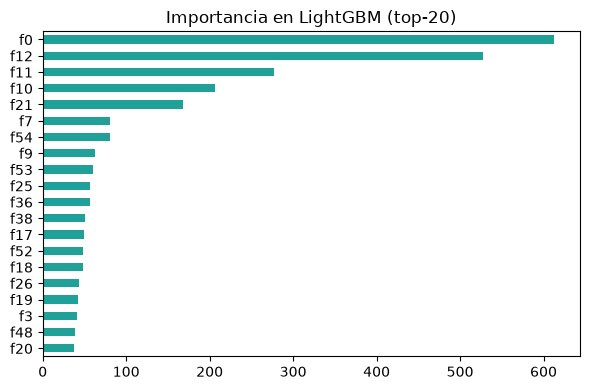

In [8]:
# Fase A — baseline tonto + importancia LGBM (SOLO lectura, no entra en la eleccion)
# Baseline: predecir siempre la media del train (motores de ajuste). Referencia pedagogica, como en clase.
baseline_val = float(dev["y"][fit_idx].mean())
pred_media = np.full_like(test["y"], baseline_val, dtype=float)
fila_base = evaluar_clase("Baseline (media train)", test["y"], pred_media)
print(f"Baseline media train = {baseline_val:.2f} ciclos")
mostrar_clase([fila_base,
               evaluar_clase("LightGBM cuantil 0.35", test["y"], p_lgb_test)])

# Importancia LGBM (solo lectura, como plantilla cell 60)
imp = pd.Series(np.asarray(lgbm.feature_importances_, dtype=float),
                index=[f"f{i}" for i in range(lgbm.n_features_in_)]).sort_values()
print(f"top-5 rasgos: {imp.tail(5).index.tolist()}")
imp.tail(20).plot.barh(figsize=(6, 4), title="Importancia en LightGBM (top-20)", color="#1FA098")
plt.tight_layout(); plt.show()


## 5 · Modelo base B — BiLSTM con triple pooling temporal

19 canales, dos capas LSTM bidireccionales de 64 unidades y una cabeza que
concatena el último paso, la media y el máximo: el estado actual, el nivel de la
trayectoria y el transitorio extremo. Se valida en el motor 16, que nunca entra
en el ajuste.


In [9]:
model = build_champion_bilstm(input_shape=dev['X_seq'].shape[1:], dense_units=32, seed=PRIMARY_SEED)
model.summary()
print()
print('parámetros:', model.count_params())


Model: "BiLSTM_TriplePooling_RUL"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_window        │ (None, 50, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_norm_input    │ (None, 50, 19)    │         76 │ input_window[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_1      │ (None, 50, 128)   │     43,008 │ batch_norm_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_2      │ (None, 50, 128)   │     98,816 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step           │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (LastStepPooling)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_pooling    │ (None, 384)       │          0 │ last_step[0][0],  │
│ (Concatenate)       │                   │            │ global_avg_pool[… │
│                     │                   │            │ global_max_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_pooled      │ (None, 384)       │          0 │ temporal_pooling… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_proj (Dense)  │ (None, 32)        │     12,320 │ dropout_pooled[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rul_output (Dense)  │ (None, 1)         │         33 │ dense_proj[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 154,253 (602.55 KB)

 Trainable params: 154,215 (602.40 KB)

 Non-trainable params: 38 (152.00 B)


parámetros: 154253


In [10]:
t0 = time.time()
result = run_seed(raw, seed=PRIMARY_SEED, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                  test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                  step_test=STEP_TEST, epochs=22)
print(f'LightGBM {result["t_lgb"]:.2f} s | BiLSTM {result["t_lstm"]:.1f} s')

hist = result['history'].history
print('épocas ejecutadas:', len(hist['loss']))
print('mejor val_loss:', round(float(min(hist['val_loss'])), 3))

m = evaluate_predictions(result['test']['y'], result['p_lstm_test'],
                         'BiLSTM triple pooling (standalone)')
print(m)


LightGBM 0.59 s | BiLSTM 166.1 s
épocas ejecutadas: 12
mejor val_loss: 10.532
{'Modelo': 'BiLSTM triple pooling (standalone)', 'RMSE': 5.637, 'MAE': 4.385, 'R2': 0.909, 'NASA_Score': 3782.6}


In [11]:
# Puente NB1 -> NB2: guarda intermedios (no cambia ningun calculo del original)
import pathlib, joblib, numpy as np
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
# dev/test contienen arrays + meta (DataFrame). Se guardan por separado para no picklear el modelo keras.
np.savez_compressed(ART / "nb1_dev.npz",
    X_seq=dev["X_seq"], X_tab=dev["X_tab"], y=dev["y"],
    X_raw=dev["X_raw"],
    meta_unit=dev["meta"]["unit"].values, meta_cycle=dev["meta"]["cycle"].values)
np.savez_compressed(ART / "nb1_test.npz",
    X_seq=test["X_seq"], X_tab=test["X_tab"], y=test["y"],
    X_raw=test["X_raw"],
    meta_unit=test["meta"]["unit"].values, meta_cycle=test["meta"]["cycle"].values)
joblib.dump({"prep": prep, "fit_idx": fit_idx, "hold_idx": hold_idx,
             "dev_units": dev_units, "lgbm": lgbm,
             "p_lgb_hold": p_lgb_hold, "p_lgb_test": p_lgb_test},
            ART / "nb1_aux.joblib")
joblib.dump({"p_lstm_hold": result["p_lstm_hold"], "p_lstm_test": result["p_lstm_test"],
             "p_lgb_hold": result["p_lgb_hold"], "p_lgb_test": result["p_lgb_test"],
             "t_lgb": result["t_lgb"], "t_lstm": result["t_lstm"],
             "history": result["history"].history},
            ART / "nb1_result_arrays.joblib")
result["bilstm"].save(ART / "bilstm_seed42.keras")
print("[NB1 OK] artefactos en", ART.resolve())
print("siguiente: abrir 02_decision_ablacion_oof_ensamble.ipynb")


[NB1 OK] artefactos en C:\Users\mikel\Desktop\Pruebas\nasa\notebooks\ds02_ensemble\artifacts
siguiente: abrir 02_decision_ablacion_oof_ensamble.ipynb
